In [1]:
import sys
sys.path.append("../src")
from openf1_client import get

In [2]:
laps = get("laps", session_key = 11406)
stints = get("stints", session_key = 11406)

merged = laps.merge(stints[["driver_number", "stint_number", "lap_start", "lap_end",
                       "compound", "tyre_age_at_start"]], on="driver_number")

print(len(laps), len(merged))

702 3036


In [4]:
laps_st = merged[(merged["lap_number"] >= merged["lap_start"]) & (merged["lap_number"] <= merged["lap_end"])]
len(laps_st)

702

In [5]:
laps_st = laps_st.copy()
laps_st["tyre_age"] = laps_st["tyre_age_at_start"] + (laps_st["lap_number"] - laps_st["lap_start"])


In [7]:
laps_st = laps_st.copy()
laps_st["is_pit_in_lap"] = laps_st["lap_number"] == laps_st["lap_end"]
print(laps_st["is_pit_in_lap"].sum())

91


In [8]:
not_out  = ~laps_st["is_pit_out_lap"]
not_in   = ~laps_st["is_pit_in_lap"]
has_time = laps_st["lap_duration"].notna()

keep = not_out & not_in & has_time
clean = laps_st[keep].copy()
print(len(clean))

522


<Axes: title={'center': 'São Paulo FP2 - Leclerc (clean laps)'}, xlabel='Lap number', ylabel='Lap time (s)'>

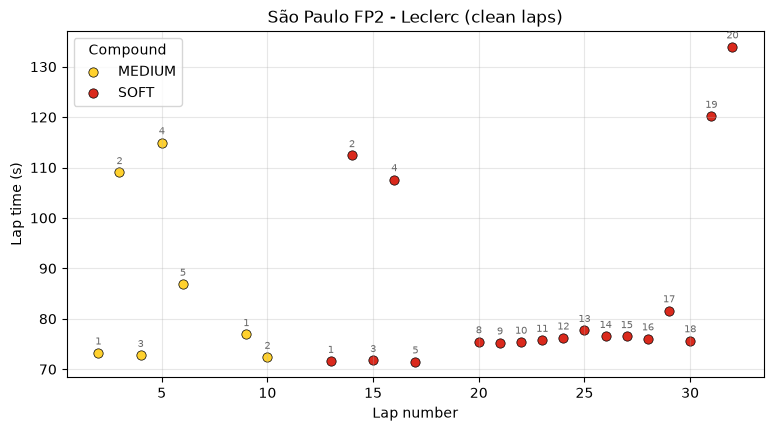

In [9]:
from plots import plot_driver_laps

plot_driver_laps(clean, 16, "São Paulo FP2 - Leclerc (clean laps)")

**Conclusion:** I have correlated each lap with each stint per driver. The graphic shows a long run between laps 20-30, on soft tyres, with a fast paced aproach on the first three laps with softs. 